In [24]:
import cv2
import numpy as np
import os
from google.colab import files
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import urllib.request

BaseOptions = mp.tasks.BaseOptions
FaceDetector = mp.tasks.vision.FaceDetector
FaceDetectorOptions = mp.tasks.vision.FaceDetectorOptions
FaceDetectorResult = mp.tasks.vision.FaceDetectorResult
VisionRunningMode = mp.tasks.vision.RunningMode

print("All Libraries Loaded Successfully")
print(f"MediaPipe Version: {mp.__version__}")

All Libraries Loaded Successfully
MediaPipe Version: 1.2.2


In [22]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"Uploaded File: {filename}")

image_files = [f for f in os.listdir('images') if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
print(f"\nUploaded Files: {image_files}")

Saving akhavan.jpg to akhavan.jpg
Uploaded File: akhavan.jpg

Uploaded Files: ['akhavan.jpg']


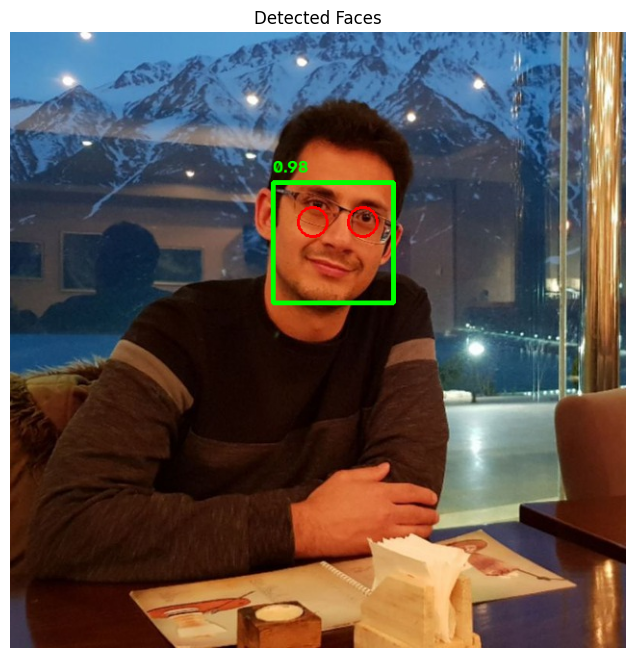

In [26]:
if image_files:
  image_path = os.path.join('images', image_files[0])

  model_url = 'https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite'
  model_path = 'blaze_face_short_range.tflite'

  if not os.path.exists(model_path):
    print("Downloading MediaPipe Face Detector Model...")
    urllib.request.urlretrieve(model_url, model_path)
    print("Download Complete.")

  base_options = python.BaseOptions(model_asset_path=model_path)
  options = vision.FaceDetectorOptions(base_options=base_options, running_mode=vision.RunningMode.IMAGE, min_detection_confidence=0.5)

  with vision.FaceDetector.create_from_options(options) as detector:
    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image_rgb)

    detection_result = detector.detect(mp_image)

    h, w, c = image.shape

    if detection_result.detections:
      for detection in detection_result.detections:
        bbox = detection.bounding_box
        x = int(bbox.origin_x)
        y = int(bbox.origin_y)
        w = int(bbox.width)
        h = int(bbox.height)

        cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 3)

        eye_y = y + h // 3
        left_eye_x = x + w // 3
        right_eye_x = x + (3 * w) // 4
        eye_radius = max(w // 8, 5)

        cv2.circle(image, (left_eye_x, eye_y), eye_radius, (0, 0, 255), 2)
        cv2.circle(image, (right_eye_x, eye_y), eye_radius, (0, 0, 255), 2)

        confidence = detection.categories[0].score
        cv2.putText(image, f"{confidence:.2f}", (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

  plt.figure(figsize=(12, 8))

  plt.imshow(image[..., ::-1])
  num_faces = len(detection_result.detections) if detection_result.detections else 0
  plt.title('Detected Faces')
  plt.axis('off')

  plt.show()